## CUDA / MIG setup (run first)

On this host, GPU access is via a reserved MIG slice (`gpu-shell`). `CUDA_VISIBLE_DEVICES` must point at **your current** slice UUID.

Jupyter kernels do **not** inherit env changes from an interactive terminal. If you reserved a new slice (or the old UUID expired / was reassigned), a kernel started earlier still has the stale CVD and `torch.cuda.is_available()` will be False.

**Fix:** run the next cell **before** any `import torch`, then **Restart Kernel** and re-run from the top if torch was already imported.

In [26]:
# MUST run before any `import torch`. CVD is read at CUDA init; changing it later has no effect.
import os
import re
from pathlib import Path

_slice_file = Path(f"/run/gpu-slice/{os.environ.get('USER', '')}")
_cvd_before = os.environ.get("CUDA_VISIBLE_DEVICES")
_synced_from = None

if _slice_file.is_file():
    # gpu-slice stub may export CVD; apply before torch sees the GPU.
    _text = _slice_file.read_text()
    _m = re.search(r"export\s+CUDA_VISIBLE_DEVICES=(\S+)", _text)
    if _m:
        _live = _m.group(1).strip().strip("'\"")
        if _cvd_before != _live:
            os.environ["CUDA_VISIBLE_DEVICES"] = _live
            _synced_from = str(_slice_file)

print("CUDA_VISIBLE_DEVICES (before):", _cvd_before)
print("CUDA_VISIBLE_DEVICES (now):   ", os.environ.get("CUDA_VISIBLE_DEVICES"))
if _synced_from:
    print(f"Synced CVD from {_synced_from}")
    print("If torch was already imported in this kernel: Kernel → Restart, then re-run from this cell.")

import torch

print("torch.cuda.is_available():", torch.cuda.is_available())
print("torch.cuda.device_count():", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device 0:", torch.cuda.get_device_name(0))
else:
    print(
        "CUDA still unavailable. In a terminal:\n"
        "  source /run/gpu-slice/$USER   # or: gpu-shell status / gpu-shell dev\n"
        "  echo $CUDA_VISIBLE_DEVICES\n"
        "Then restart this kernel (Cursor must pick up the env), or re-run this cell after sync on a fresh kernel.\n"
        "Do not hardcode a MIG UUID — it changes every reservation."
    )


CUDA_VISIBLE_DEVICES (before): MIG-c677e9e9-7e7e-5170-9d9c-4013b984cf6a
CUDA_VISIBLE_DEVICES (now):    MIG-c677e9e9-7e7e-5170-9d9c-4013b984cf6a
torch.cuda.is_available(): True
torch.cuda.device_count(): 1
device 0: NVIDIA H200 MIG 3g.71gb


## Bench helper


In [ ]:
import torch


def bench(fn, *args, warmup=10, iters=50):
    """Time fn(*args) with CUDA events; return ms/iter."""
    for _ in range(warmup):
        _ = fn(*args)
    torch.cuda.synchronize()  # exclude warmup from the timed window
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    start.record()
    for _ in range(iters):
        _ = fn(*args)
    end.record()
    torch.cuda.synchronize()  # wait for end event before reading elapsed_time
    return start.elapsed_time(end) / iters  # ms over iters -> ms/iter

PROFILE_COMPILE = True  # set False to skip torch.compile timings everywhere
VERBOSE = False  # set True to print per-iters sweep stats and overhead lines
# --- shared config ---
WARMUP = 5
ITERS = 100
MATMUL_SIZE_SWEEP = [64, 128, 256, 512, 1024, 2048, 4096]
COMPILE_WARMUP = 20  # longer warmup for torch.compile JIT before timed bench
COMPILE_ITERS = 100  # prime compile graph; measured bench uses WARMUP/ITERS below
MATMUL_DTYPE_SWEEP_N = 1024
MATMUL_DTYPE_SWEEP_N_LARGE = 4096
MATMUL_DTYPES = (
    torch.float32,
    torch.float16,
    torch.bfloat16,
    torch.float64,
    torch.complex64,
    torch.complex128,
    torch.int32,
    torch.int64,
)


## Matmul: size sweep (fixed iters/warmup)


  N=   64: 10.92 us/iter, compile 41.09 us/iter
  N=  128: 10.54 us/iter, compile 40.31 us/iter
  N=  256: 11.87 us/iter, compile 39.95 us/iter
  N=  512: 24.26 us/iter, compile 44.03 us/iter
  N= 1024: 119.30 us/iter, compile 119.66 us/iter


  N= 2048: 911.26 us/iter, compile 911.44 us/iter
  N= 4096: 6928.15 us/iter, compile 6929.63 us/iter


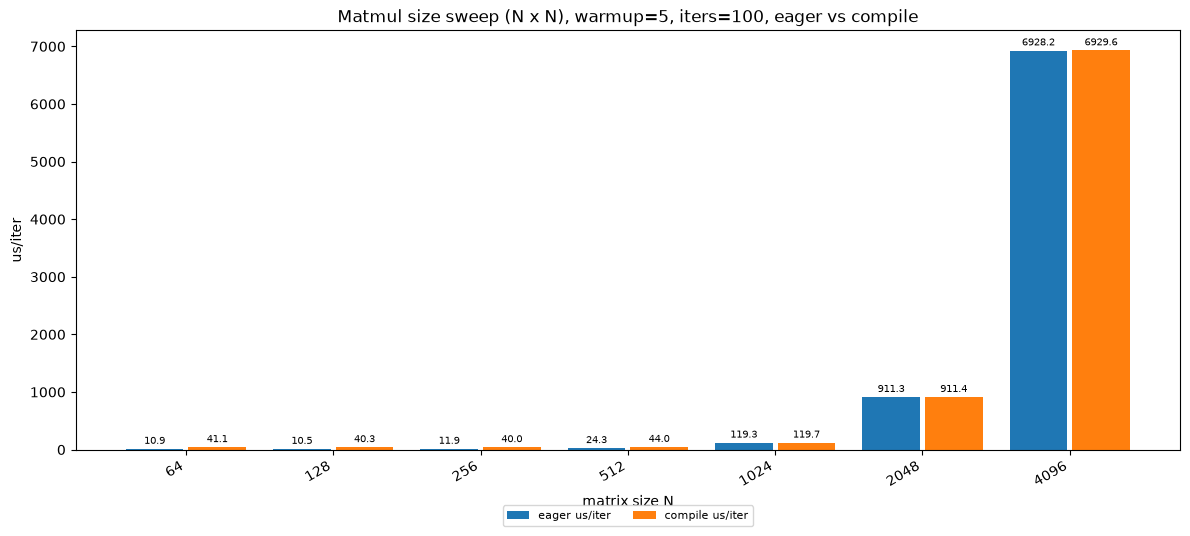

In [28]:
import matplotlib.pyplot as plt

# Square matmul size sweep: fixed warmup/iters, eager (+ compile if PROFILE_COMPILE)
if not torch.cuda.is_available():
    print("CUDA unavailable; skipping matmul size sweep")
else:
    sizes_ok = []  # N values that alloc+bench succeeded (OOM sizes skipped)
    us_per_iter = []
    sizes_compile = []
    us_compile_per_iter = []

    if VERBOSE:
        print(f"torch.matmul (N x N) @ (N x N), warmup={WARMUP}, iters={ITERS}")

    for n in MATMUL_SIZE_SWEEP:
        try:
            a = torch.randn(n, n, device="cuda")
            b = torch.randn(n, n, device="cuda")
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            print(f"skip {n}x{n} matmul size sweep: OOM during alloc")
            continue

        ms = bench(torch.matmul, a, b, warmup=WARMUP, iters=ITERS)  # fixed ITERS, not COMPILE_ITERS
        us = ms * 1000
        sizes_ok.append(n)
        us_per_iter.append(us)
        line = f"  N={n:5d}: {us:.2f} us/iter"

        if PROFILE_COMPILE:
            try:
                compiled = torch.compile(torch.matmul)
                bench(compiled, a, b, warmup=COMPILE_WARMUP, iters=COMPILE_ITERS)  # JIT compile before timed run
                ms_c = bench(compiled, a, b, warmup=WARMUP, iters=ITERS)  # same WARMUP/ITERS as eager
                us_c = ms_c * 1000
                sizes_compile.append(n)
                us_compile_per_iter.append(us_c)
                line += f", compile {us_c:.2f} us/iter"
            except Exception as e:
                if VERBOSE:
                    print(f"  N={n:5d}: compile skipped ({type(e).__name__}: {e})")

        print(line)

    if sizes_ok:
        fig = plt.figure(figsize=(12, 6))
        xpos = list(range(len(sizes_ok)))
        series = [("eager us/iter", us_per_iter)]
        if PROFILE_COMPILE and sizes_compile:
            compile_by_n = dict(zip(sizes_compile, us_compile_per_iter))  # map compile results onto sizes_ok x-axis
            series.append(
                (
                    "compile us/iter",
                    [compile_by_n.get(n, float("nan")) for n in sizes_ok],
                )
            )
        n_bars = len(series)
        group_w, bar_w = 0.85, 0.85 / n_bars
        ax = fig.gca()
        for i, (name, vals) in enumerate(series):
            xs = [xi - group_w / 2 + bar_w / 2 + i * bar_w for xi in xpos]
            kw = {"width": bar_w * 0.92, "label": name}
            if name == "eager us/iter":
                kw["color"] = "#1f77b4"
            elif name == "compile us/iter":
                kw["color"] = "#ff7f0e"
            bars = ax.bar(xs, vals, **kw)
            ax.bar_label(
                bars,
                labels=[f"{v:.1f}" if v == v else "" for v in vals],
                fontsize=7,
                padding=2,
            )
        plt.xticks(xpos, [str(n) for n in sizes_ok], rotation=30, ha="right")
        plt.xlabel("matrix size N")
        plt.ylabel("us/iter")
        title = f"Matmul size sweep (N x N), warmup={WARMUP}, iters={ITERS}"
        if PROFILE_COMPILE:
            title += ", eager vs compile"
        plt.title(title)
        ncol = 2 if PROFILE_COMPILE and sizes_compile else 1
        plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=ncol, fontsize=8)
        fig.tight_layout(rect=(0, 0.08, 1, 1))
        plt.show()


## Matmul: dtype sweep (fixed N)


  float32 : 119.29 us/iter, compile 119.58 us/iter
  float16 : 9.94 us/iter, compile 36.96 us/iter
  bfloat16: 10.24 us/iter, compile 39.49 us/iter
  float64 : 87.07 us/iter, compile 87.22 us/iter
  complex64: 406.48 us/iter, compile 406.15 us/iter
  complex128: 322.95 us/iter, compile 323.67 us/iter
skip int32: matmul failed (NotImplementedError: "addmm_cuda" not implemented for 'Int')
skip int64: matmul failed (NotImplementedError: "addmm_cuda" not implemented for 'Long')


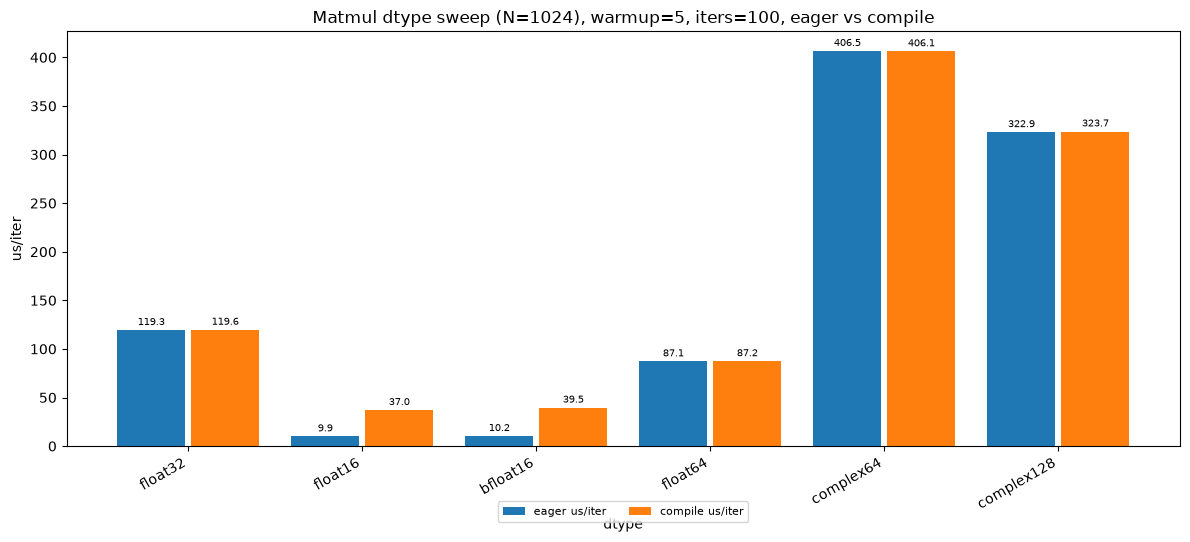

  float32 : 6929.68 us/iter, compile 6929.05 us/iter
  float16 : 341.55 us/iter, compile 341.91 us/iter
  bfloat16: 340.85 us/iter, compile 341.47 us/iter
  float64 : 4744.18 us/iter, compile 4800.69 us/iter
  complex64: 23082.32 us/iter, compile 23068.85 us/iter
  complex128: 19757.77 us/iter, compile 19970.51 us/iter
skip int32: matmul failed (NotImplementedError: "addmm_cuda" not implemented for 'Int')
skip int64: matmul failed (NotImplementedError: "addmm_cuda" not implemented for 'Long')


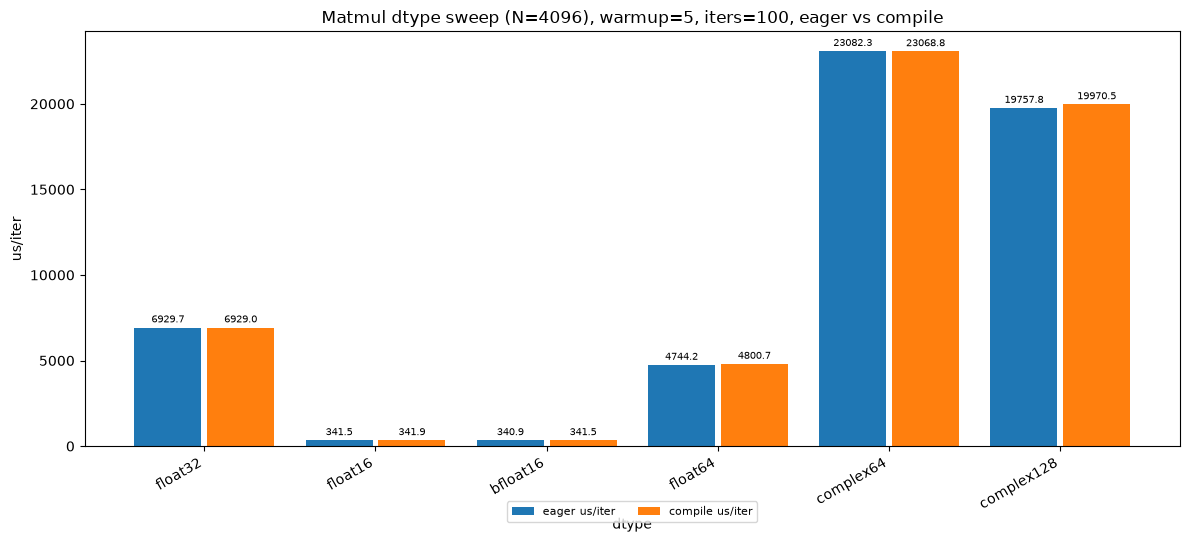

In [29]:
import matplotlib.pyplot as plt


def run_dtype_sweep(n):
    dtypes_ok = []  # dtype names that alloc+bench succeeded (unsupported/OOM skipped)
    us_per_iter = []
    dtypes_compile = []
    us_compile_per_iter = []

    if VERBOSE:
        print(f"torch.matmul ({n} x {n}) @ ({n} x {n}), warmup={WARMUP}, iters={ITERS}")

    for dtype in MATMUL_DTYPES:
        dtype_name = str(dtype).replace("torch.", "")
        if dtype is torch.bfloat16 and not torch.cuda.is_bf16_supported():
            print(f"skip {dtype_name}: bfloat16 not supported on this GPU")
            continue
        try:
            if dtype in (torch.int32, torch.int64):
                # integer matmul needs integer tensors; randn is invalid for these dtypes
                a = torch.randint(-128, 128, (n, n), device="cuda", dtype=dtype)
                b = torch.randint(-128, 128, (n, n), device="cuda", dtype=dtype)
            else:
                a = torch.randn(n, n, device="cuda", dtype=dtype)
                b = torch.randn(n, n, device="cuda", dtype=dtype)
        except (RuntimeError, torch.cuda.OutOfMemoryError) as e:
            torch.cuda.empty_cache()
            if "out of memory" in str(e).lower() or isinstance(e, torch.cuda.OutOfMemoryError):
                print(f"skip {dtype_name}: OOM during alloc")
            else:
                print(f"skip {dtype_name}: {type(e).__name__}: {e}")
            continue

        try:
            ms = bench(torch.matmul, a, b, warmup=WARMUP, iters=ITERS)
        except Exception as e:
            torch.cuda.empty_cache()
            print(f"skip {dtype_name}: matmul failed ({type(e).__name__}: {e})")
            continue

        us = ms * 1000
        dtypes_ok.append(dtype_name)
        us_per_iter.append(us)
        line = f"  {dtype_name:8s}: {us:.2f} us/iter"

        if PROFILE_COMPILE:
            try:
                compiled = torch.compile(torch.matmul)
                bench(compiled, a, b, warmup=COMPILE_WARMUP, iters=COMPILE_ITERS)  # JIT compile before timed run
                ms_c = bench(compiled, a, b, warmup=WARMUP, iters=ITERS)  # same WARMUP/ITERS as eager
                us_c = ms_c * 1000
                dtypes_compile.append(dtype_name)
                us_compile_per_iter.append(us_c)
                line += f", compile {us_c:.2f} us/iter"
            except Exception as e:
                if VERBOSE:
                    print(f"  {dtype_name}: compile skipped ({type(e).__name__}: {e})")

        print(line)
        del a, b
        torch.cuda.empty_cache()  # drop dtype tensors before next (large N) alloc

    if not dtypes_ok:
        return

    fig = plt.figure(figsize=(12, 6))
    xpos = list(range(len(dtypes_ok)))
    series = [("eager us/iter", us_per_iter)]
    if PROFILE_COMPILE and dtypes_compile:
        compile_by_dt = dict(zip(dtypes_compile, us_compile_per_iter))  # map compile results onto dtypes_ok x-axis
        series.append(
            (
                "compile us/iter",
                [compile_by_dt.get(d, float("nan")) for d in dtypes_ok],
            )
        )
    n_bars = len(series)
    group_w, bar_w = 0.85, 0.85 / n_bars
    ax = fig.gca()
    for i, (name, vals) in enumerate(series):
        xs = [xi - group_w / 2 + bar_w / 2 + i * bar_w for xi in xpos]
        kw = {"width": bar_w * 0.92, "label": name}
        if name == "eager us/iter":
            kw["color"] = "#1f77b4"
        elif name == "compile us/iter":
            kw["color"] = "#ff7f0e"
        bars = ax.bar(xs, vals, **kw)
        ax.bar_label(
            bars,
            labels=[f"{v:.1f}" if v == v else "" for v in vals],
            fontsize=7,
            padding=2,
        )
    plt.xticks(xpos, dtypes_ok, rotation=30, ha="right")
    plt.xlabel("dtype")
    plt.ylabel("us/iter")
    title = f"Matmul dtype sweep (N={n}), warmup={WARMUP}, iters={ITERS}"
    if PROFILE_COMPILE:
        title += ", eager vs compile"
    plt.title(title)
    ncol = 2 if PROFILE_COMPILE and dtypes_compile else 1
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=ncol, fontsize=8)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()


# Matmul dtype sweep at fixed N: eager (+ compile if PROFILE_COMPILE)
if not torch.cuda.is_available():
    print("CUDA unavailable; skipping matmul dtype sweep")
else:
    for n in (MATMUL_DTYPE_SWEEP_N, MATMUL_DTYPE_SWEEP_N_LARGE):
        run_dtype_sweep(n)
